# Salary Prediction: Model Training
This notebook builds the regression model used by the Streamlit app (`app.py`).

**Goal:** predict `Salary` from `Experience Years`.  
**Workflow:** load data, explore, check and clean, split, train and compare models, evaluate, save the model with `joblib`.

In [1]:
import json
from pathlib import Path
import numpy as np, pandas as pd
import matplotlib.pyplot as plt, seaborn as sns
import joblib, sklearn
from sklearn.model_selection import train_test_split, KFold, cross_val_score
from sklearn.linear_model import LinearRegression
from sklearn.preprocessing import PolynomialFeatures
from sklearn.pipeline import make_pipeline
from sklearn.metrics import r2_score, mean_absolute_error, mean_squared_error

sns.set_theme(style='whitegrid')
ROOT = Path('..') if Path('../data').exists() else Path('.')       # works from notebooks/ or the project root
DATA, MODEL_DIR = ROOT/'data'/'salary_dataset.csv', ROOT/'model'

## 1. Load and explore the data

In [2]:
df = pd.read_csv(DATA)
print('Shape:', df.shape)
display(df.head()); display(df.describe().T)
df.info()

Shape: (200, 2)


,Experience Years,Salary
0,0.6,27868
1,0.6,31381
2,0.7,44204
3,0.8,39551
4,0.9,25984


,count,mean,std,min,25%,50%,75%,max
Experience Years,200.0,7.519,4.279792,0.6,3.8,7.7,11.5,14.8
Salary,200.0,96834.455,40938.012116,25984.0,60248.5,94732.0,132854.5,173265.0


<class 'pandas.DataFrame'>
RangeIndex: 200 entries, 0 to 199
Data columns (total 2 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   Experience Years  200 non-null    float64
 1   Salary            200 non-null    int64  
dtypes: float64(1), int64(1)
memory usage: 3.3 KB


## 2. Data quality checks

In [3]:
print('Missing values:\n', df.isna().sum(), '\n')
print('Duplicate rows:', df.duplicated().sum())
print('Negative values:', (df < 0).sum().sum())
print('Is the file sorted by experience?', df['Experience Years'].is_monotonic_increasing)

Missing values:
 Experience Years    0
Salary              0
dtype: int64 

Duplicate rows: 0
Negative values: 0
Is the file sorted by experience? True


**Findings:** 200 rows, two numeric columns, no missing values, no duplicate rows and no negative values. No cleaning is needed. Salary values are in the units given in the dataset (the currency is not specified).

**Important detail:** the file is **sorted by experience**. This matters for validation: a plain 5-fold cross-validation without shuffling would train on low-experience rows and test on high-experience rows (pure extrapolation), giving misleadingly poor scores. The splits below are therefore shuffled.

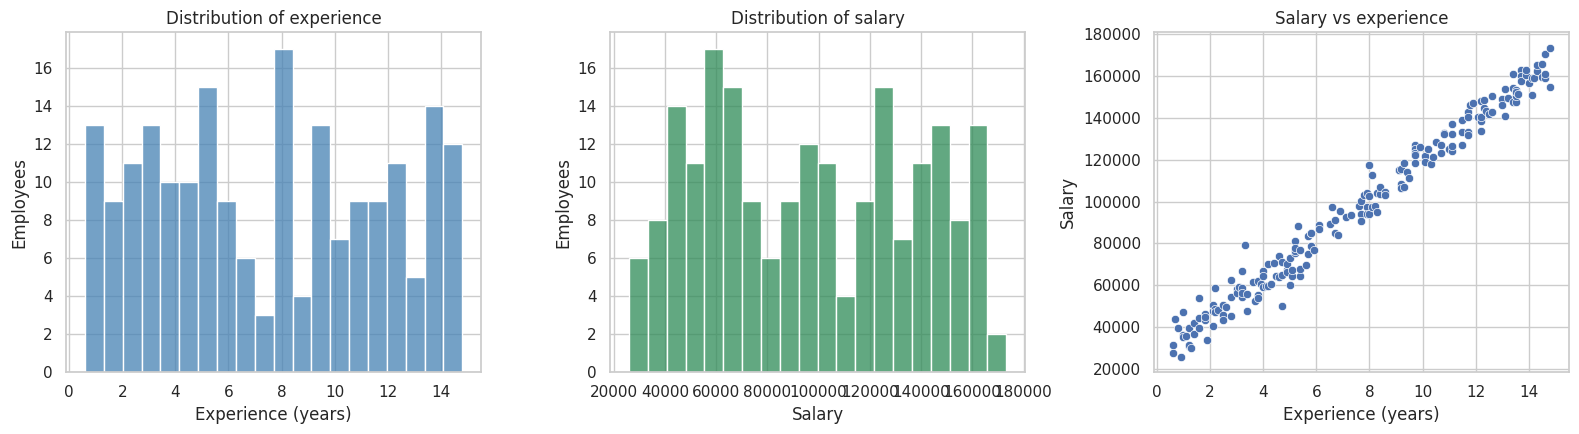

Pearson correlation: 0.99


In [4]:
fig, ax = plt.subplots(1, 3, figsize=(16, 4.5))
sns.histplot(df['Experience Years'], bins=20, ax=ax[0], color='steelblue'); ax[0].set(title='Distribution of experience', xlabel='Experience (years)', ylabel='Employees')
sns.histplot(df['Salary'], bins=20, ax=ax[1], color='seagreen'); ax[1].set(title='Distribution of salary', xlabel='Salary', ylabel='Employees')
sns.scatterplot(data=df, x='Experience Years', y='Salary', ax=ax[2]); ax[2].set(title='Salary vs experience', xlabel='Experience (years)', ylabel='Salary')
plt.tight_layout(); plt.show()
print('Pearson correlation:', round(df['Experience Years'].corr(df['Salary']), 3))

The relationship is very strongly positive and close to a straight line (r of about 0.99), so a linear regression is a natural, interpretable first choice. Residual spread looks roughly constant across experience, which suits ordinary least squares.

## 3. Features, target and train/test split

In [5]:
FEATURE, TARGET = 'Experience Years', 'Salary'
X, y = df[[FEATURE]], df[TARGET]
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
print(f'Train: {len(X_train)} rows | Test: {len(X_test)} rows')

Train: 160 rows | Test: 40 rows


## 4. Train and compare models
A linear model is compared with polynomial versions to check whether extra complexity helps. All are scored on the held-out test set and with shuffled 5-fold cross-validation on the full data.

In [6]:
def metrics(model, Xte, yte):
    p = model.predict(Xte)
    return {'R2': r2_score(yte, p), 'MAE': mean_absolute_error(yte, p), 'RMSE': np.sqrt(mean_squared_error(yte, p))}

candidates = {'Linear regression': LinearRegression(),
              'Polynomial (degree 2)': make_pipeline(PolynomialFeatures(2), LinearRegression()),
              'Polynomial (degree 3)': make_pipeline(PolynomialFeatures(3), LinearRegression())}
cv = KFold(n_splits=5, shuffle=True, random_state=42)
rows = []
for name, m in candidates.items():
    m.fit(X_train, y_train)
    rows.append({'Model': name, **{f'Test {k}': v for k, v in metrics(m, X_test, y_test).items()},
                 'CV R2 (mean)': cross_val_score(m, X, y, cv=cv, scoring='r2').mean()})
comparison = pd.DataFrame(rows).set_index('Model')
display(comparison.style.format({'Test R2': '{:.4f}', 'Test MAE': '{:,.0f}', 'Test RMSE': '{:,.0f}', 'CV R2 (mean)': '{:.4f}'}))

,Test R2,Test MAE,Test RMSE,CV R2 (mean)
Model,,,,
Linear regression,0.9831,"4,056","4,873",0.9796
Polynomial (degree 2),0.9834,"4,032","4,830",0.9797
Polynomial (degree 3),0.9841,"3,963","4,739",0.9800


**Model choice:** all three models perform almost identically (test R² about 0.98 for each). The polynomial versions add complexity without a meaningful gain, so the **simple linear regression is selected**: it is easier to explain ("each extra year of experience adds about X to salary"), less likely to overfit, and extrapolates more sensibly.

## 5. Evaluate the chosen model

In [7]:
model = LinearRegression().fit(X_train, y_train)
test = metrics(model, X_test, y_test)
cv_scores = cross_val_score(LinearRegression(), X, y, cv=cv, scoring='r2')

print(f"Test R2   : {test['R2']:.4f}")
print(f"Test MAE  : {test['MAE']:,.0f}")
print(f"Test RMSE : {test['RMSE']:,.0f}")
print(f"CV R2     : {cv_scores.mean():.4f} (+/- {cv_scores.std():.4f}) over 5 shuffled folds")
print(f"Intercept : {model.intercept_:,.0f} | Coefficient: {model.coef_[0]:,.0f} per year of experience")

# Why shuffling matters here (the file is sorted by experience)
naive = cross_val_score(LinearRegression(), X, y, cv=5, scoring='r2')
print('\nUnshuffled 5-fold CV R2 per fold (misleading because data is sorted):', naive.round(2))

Test R2   : 0.9831
Test MAE  : 4,056
Test RMSE : 4,873
CV R2     : 0.9796 (+/- 0.0046) over 5 shuffled folds
Intercept : 25,755 | Coefficient: 9,438 per year of experience

Unshuffled 5-fold CV R2 per fold (misleading because data is sorted): [0.55 0.24 0.77 0.75 0.68]


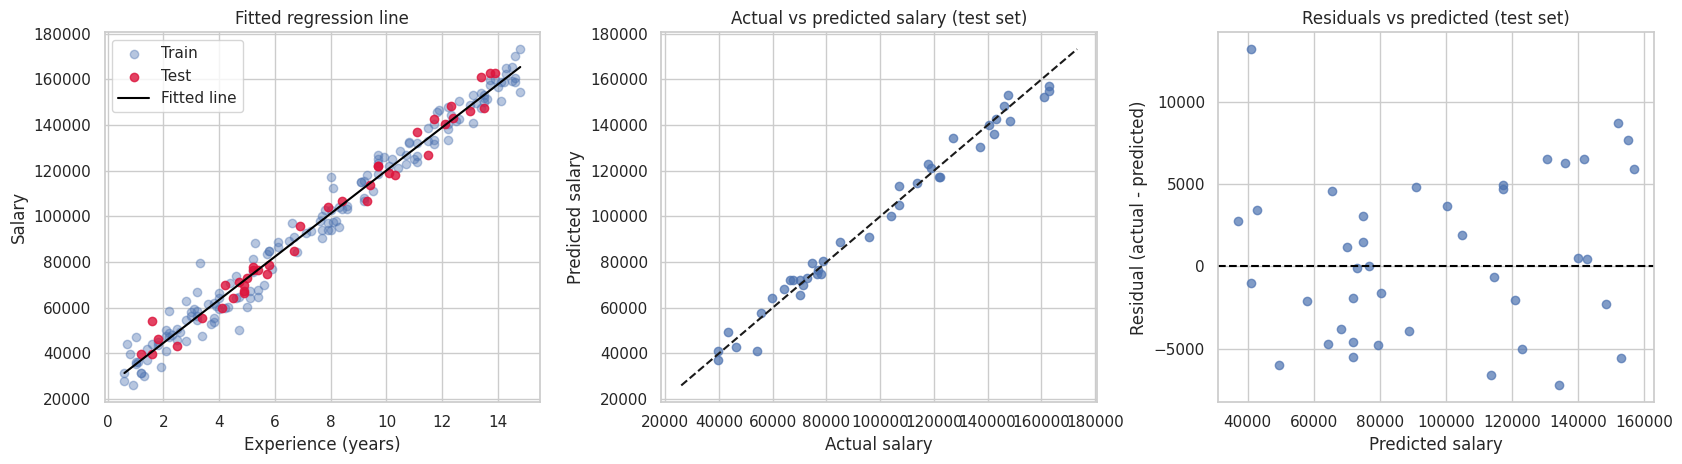

In [8]:
pred = model.predict(X_test); resid = y_test - pred
fig, ax = plt.subplots(1, 3, figsize=(17, 4.8))
grid = pd.DataFrame({FEATURE: np.linspace(df[FEATURE].min(), df[FEATURE].max(), 100)})
ax[0].scatter(X_train, y_train, alpha=.4, label='Train'); ax[0].scatter(X_test, y_test, alpha=.8, color='crimson', label='Test')
ax[0].plot(grid, model.predict(grid), color='black', label='Fitted line')
ax[0].set(title='Fitted regression line', xlabel='Experience (years)', ylabel='Salary'); ax[0].legend()
ax[1].scatter(y_test, pred, alpha=.7); lim = [y.min(), y.max()]; ax[1].plot(lim, lim, 'k--')
ax[1].set(title='Actual vs predicted salary (test set)', xlabel='Actual salary', ylabel='Predicted salary')
ax[2].scatter(pred, resid, alpha=.7); ax[2].axhline(0, color='black', ls='--')
ax[2].set(title='Residuals vs predicted (test set)', xlabel='Predicted salary', ylabel='Residual (actual - predicted)')
plt.tight_layout(); plt.show()

**Interpretation:** the model explains about 98% of the variation in salary on unseen data, with a typical error (MAE) of roughly 4,000 and RMSE of roughly 4,900. Residuals scatter evenly around zero with no obvious curve or funnel, so a linear model is appropriate. The result is consistent across shuffled folds.

**Limitations:** experience is the only feature, so factors such as role, education, location or company are not captured. Predictions are only reliable inside the training range (about 0.6 to 14.8 years); the app warns the user outside it.

## 6. Retrain on all data and save the model
The evaluation above used a train/test split. For the deployed model, the same algorithm is refit on **all 200 rows** (the validated approach) and saved with `joblib`. The metrics above are stored alongside it so the app can display them.

In [9]:
final_model = LinearRegression().fit(X, y)
MODEL_DIR.mkdir(exist_ok=True)
joblib.dump(final_model, MODEL_DIR/'model.pkl')

info = {'model': 'LinearRegression', 'feature': FEATURE, 'target': TARGET, 'n_rows': int(len(df)),
        'test_r2': float(test['R2']), 'test_mae': float(test['MAE']), 'test_rmse': float(test['RMSE']),
        'cv_r2_mean': float(cv_scores.mean()), 'cv_r2_std': float(cv_scores.std()),
        'coef': float(final_model.coef_[0]), 'intercept': float(final_model.intercept_),
        'min_experience': float(df[FEATURE].min()), 'max_experience': float(df[FEATURE].max()),
        'sklearn_version': sklearn.__version__}
(MODEL_DIR/'metrics.json').write_text(json.dumps(info, indent=2))

# Verify the saved model loads and predicts
loaded = joblib.load(MODEL_DIR/'model.pkl')
check = loaded.predict(pd.DataFrame({FEATURE: [5.0]}))[0]
print(f'Saved model.pkl and metrics.json. Sanity check: 5 years of experience -> {check:,.0f}')

Saved model.pkl and metrics.json. Sanity check: 5 years of experience -> 72,983
